# 06 · Evaluación en prueba: métricas, benchmarks, bitácora y análisis de operaciones

Notebook de demostración de la parte 06 (`code/evaluate.py`, `code/plots.py`). Solo importa funciones de los módulos.
Guía: `docs/instrucciones/06_evaluacion.md`.

**Mientras la parte 05 no entregue los modelos**, aquí se evalúan las líneas base; el análisis de §3.9 se muestra con el
*siempre largo* como relleno del agente, solo para ver que la maquinaria funciona. Las cifras del agente salen de
`python main.py` cuando existan sus políticas.

In [1]:
import sys
sys.path.insert(0, "..")
sys.modules.pop("code", None)  # IPython ya importó el módulo `code` estándar (ver docs/decisiones.md)

import pandas as pd
from IPython.display import Image, display

from code import data, env, evaluate
from main import BTC_CSV, FOLDS, SEED, SP500_CSV

ohlcv, _ = data.load_ohlcv(BTC_CSV)
features = data.compute_features(ohlcv)
sp500 = data.load_sp500(SP500_CSV)   # solo benchmark (§3.7), snapshot versionado
pd.set_option("display.width", 200)

## 1. Benchmarks con costos

Comprar y mantener paga 0.125 % al entrar y al salir, con la misma contabilidad del entorno. BTC compra a la apertura
de la primera barra de la prueba; el S&P 500 (`^GSPC`, índice de precios) en el primer cierre del periodo.

In [2]:
fold = data.build_fold_dataset(ohlcv, features, 3, FOLDS[3])
btc = fold.ohlcv["test"]
equity, log = evaluate.buy_and_hold(btc["close"], btc.index[0], btc.index[-1], env.COST_PER_SIDE, entry=btc["open"].iloc[0])
log[["entry_time", "exit_time", "entry_price", "exit_price", "gross_pnl", "costs", "net_pnl"]]

,entry_time,exit_time,entry_price,exit_price,gross_pnl,costs,net_pnl
0,2025-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,93576.0,87648.22,-0.063347,0.002421,-0.065768


## 2. Una prueba completa: estrategias y benchmarks en el mismo calendario

Las métricas se calculan sobre el capital al final de cada día calendario (365 días al año): BTC opera 24/7 y el S&P 500
repite su último cierre en fines de semana y feriados (rendimiento 0 esos días).

In [3]:
policies = {evaluate.AGENT: evaluate.baseline_policies(3, SEED)["siempre_largo"], **evaluate.baseline_policies(3, SEED)}
results = evaluate.evaluate_test_fold(fold, policies, sp500, FOLDS[3]["test"], SEED, env.COST_PER_SIDE)
table = pd.DataFrame({name: evaluate.performance_metrics(r["daily"], r["trades"]) for name, r in results.items()}).T
table.round(3)

,total_return,annual_return,annual_volatility,sharpe,sortino,max_drawdown,calmar,hit_rate,avg_trade_hours,turnover,n_trades
agente,-0.759,-0.759,0.421,-3.163,-3.831,-0.773,-0.982,0.467,17.305,1013.112,505.0
aleatorio,-0.646,-0.646,0.402,-2.378,-3.072,-0.670,-0.965,0.467,17.093,995.437,492.0
siempre_largo,-0.759,-0.759,0.421,-3.163,-3.831,-0.773,-0.982,0.467,17.305,1013.112,505.0
siempre_plano,0.000,0.000,0.000,NaN,NaN,0.000,NaN,NaN,NaN,0.000,0.0
btc_buy_hold,-0.066,-0.066,0.419,0.046,0.066,-0.321,-0.205,0.000,8759.000,1.786,1.0
sp500,0.164,0.164,0.187,0.904,1.343,-0.189,0.865,1.000,8712.000,2.050,1.0


## 3. Identidad contable (prueba obligatoria 4)

Capital final = capital inicial + Σ P&L neto de la bitácora (`tests/test_accounting.py`).

In [4]:
agent = results[evaluate.AGENT]
print("capital final:", agent["equity"].iloc[-1])
print("1 + Σ P&L neto:", 1 + agent["trades"]["net_pnl"].sum())
agent["trades"][["entry_time", "exit_time", "side", "exit_reason", "entry_price", "exit_price",
                 "gross_pnl", "costs", "net_pnl", "duration_hours"]].head()

capital final: 0.24063110337982188
1 + Σ P&L neto: 0.24063110337982174


,entry_time,exit_time,side,exit_reason,entry_price,exit_price,gross_pnl,costs,net_pnl,duration_hours
0,2025-01-01 01:00:00+00:00,2025-01-02 00:00:00+00:00,largo,horizonte,94401.13,95128.590000,0.007706,0.002510,0.005196,24.0
1,2025-01-02 01:00:00+00:00,2025-01-02 14:00:00+00:00,largo,take_profit,95128.59,97229.395193,0.022199,0.002541,0.019658,14.0
2,2025-01-02 15:00:00+00:00,2025-01-03 14:00:00+00:00,largo,horizonte,97256.48,97016.010000,-0.002534,0.002559,-0.005093,24.0
3,2025-01-03 15:00:00+00:00,2025-01-03 19:00:00+00:00,largo,take_profit,97016.00,98847.443128,0.019251,0.002573,0.016677,5.0
4,2025-01-03 20:00:00+00:00,2025-01-04 19:00:00+00:00,largo,horizonte,98592.02,98166.260000,-0.004476,0.002586,-0.007061,24.0


## 4. Métricas de las cuatro pruebas (`artifacts/metrics_summary.csv`)

Por fold y agregadas con media y desviación estándar entre folds (§3.6); `alpha_vs_*` es el rendimiento anualizado en
exceso sobre cada benchmark.

In [5]:
summary = pd.read_csv("../artifacts/metrics_summary.csv", index_col=[0, 1])
summary.loc[["media", "desv"], ["total_return", "annual_return", "annual_volatility", "sharpe", "sortino",
                                "max_drawdown", "calmar", "hit_rate", "turnover", "alpha_vs_btc_buy_hold",
                                "alpha_vs_sp500"]].round(3)

total_return  annual_return  annual_volatility  sharpe  sortino  max_drawdown  calmar  hit_rate  turnover  alpha_vs_btc_buy_hold  alpha_vs_sp500
fold  strategy                                                                                                                                                       
media aleatorio            -0.633         -0.683              0.442  -2.919   -3.566        -0.666  -1.098     0.459  1004.550                 -1.281          -0.879
      btc_buy_hold          0.647          0.598              0.482   0.938    1.616        -0.283   2.825     0.500     3.198                  0.000           0.402
      siempre_largo        -0.520         -0.619              0.471  -2.020   -2.587        -0.605  -1.040     0.478  1046.340                 -1.217          -0.815
      siempre_plano         0.000          0.000              0.000     NaN      NaN         0.000     NaN       NaN     0.000                 -0.598          -0.196
      sp500                 0.172          0.196              0.147   1.342    2.009        -0.117   1.888     1.000     3.119                 -0.402           0.000
desv  aleatorio             0.347          0.247              0.073   1.701    1.991         0.298   0.219     0.037    28.401                  1.082           0.285
      btc_buy_hold          0.858          0.917              0.061   1.316    2.218         0.067   4.087     0.577     2.474                  0.000           0.865
      siempre_largo         0.221          0.229              0.072   1.077    1.207         0.144   0.438     0.014    57.335                  0.731           0.189
      siempre_plano         0.000          0.000              0.000     NaN      NaN         0.000     NaN       NaN     0.000                  0.917           0.053
      sp500                 0.094          0.053              0.028   0.462    0.695         0.049   0.861     0.000     2.230                  0.865           0.000

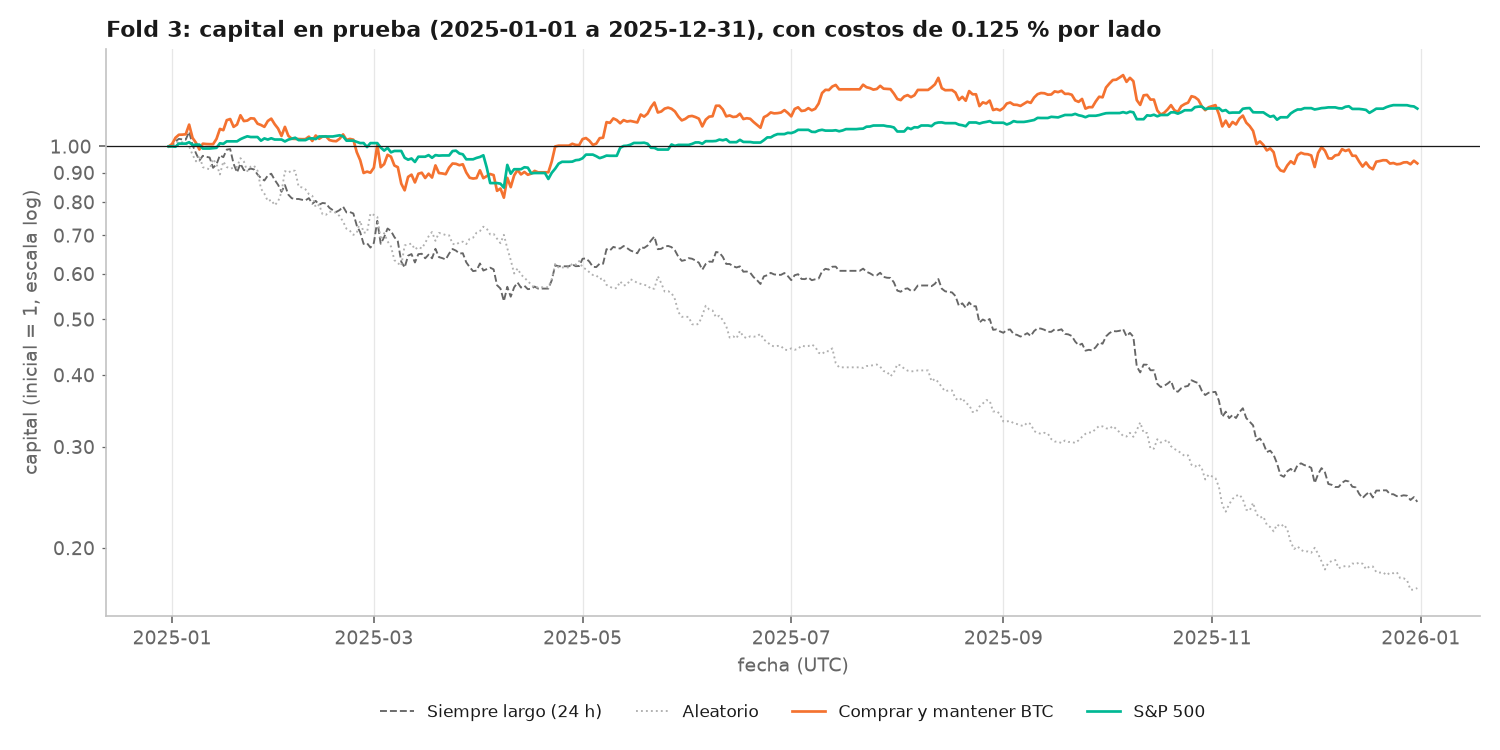

In [6]:
display(Image("../artifacts/equity_curves_test_fold_3.png", width=900))

## 5. Análisis de operaciones (§3.9), con el relleno *siempre largo*

Peores operaciones con su estado en la entrada, ventana del mayor drawdown y correlación con BTC. Con el agente real,
`main.py` escribe esto en `trade_analysis.json` y `max_drawdown_fold_{k}.png`.

In [7]:
worst = evaluate.worst_trades({3: agent["trades"]}, {3: fold.raw_features["test"]})
worst[["fold", "entry_time", "entry_price", "exit_time", "exit_price", "exit_reason", "net_return",
       "state_ret_24h", "state_rv_24h", "state_belief_drift_t", "state_drawdown_720h"]]

,fold,entry_time,entry_price,exit_time,exit_price,exit_reason,net_return,state_ret_24h,state_rv_24h,state_belief_drift_t,state_drawdown_720h
94,3,2025-03-03 17:00:00+00:00,90154.00,2025-03-04 01:00:00+00:00,84761.758079,stop,-0.062237,-0.011536,0.013541,-0.256359,-0.118406
99,3,2025-03-07 15:00:00+00:00,90440.74,2025-03-08 01:00:00+00:00,85421.253933,stop,-0.057931,0.007065,0.013960,-0.036646,-0.092971
32,3,2025-01-20 07:00:00+00:00,107482.36,2025-01-20 17:00:00+00:00,101655.273713,stop,-0.056647,0.018007,0.013295,1.247564,0.000000


In [8]:
window = evaluate.max_drawdown_window(agent["equity"])
print(window)
print(evaluate.return_correlation(agent["daily"], results["btc_buy_hold"]["daily"]))

{'peak': Timestamp('2025-01-06 15:00:00+0000', tz='UTC'), 'trough': Timestamp('2025-12-31 23:00:00+0000', tz='UTC'), 'recovery': None, 'max_drawdown': -0.7731849437794461}
{'correlation': 0.9573024357781467, 'beta': 0.9633170772761092, 'n_days': 365}
